# Phân cụm các quốc gia theo mức độ phát triển kinh tế – xã hội bằng K-Means

**Nguồn:** Our World in Data (OWID)  
**Năm mặc định:** 2023  
**Môi trường:** Google Colab / Jupyter Notebook / JupyterLab

Notebook dùng 5 đặc trưng cho K-Means:

1. GDP bình quân đầu người (PPP)
2. Tuổi thọ trung bình
3. Số năm đi học trung bình
4. Tỷ lệ dân số sử dụng Internet
5. Tỷ lệ dân số tiếp cận điện

**HDI không được dùng để phân cụm.** HDI chỉ được dùng ở cuối để đối chiếu kết quả.

## 1. Import thư viện

Nếu môi trường thiếu thư viện, bỏ dấu `#` ở dòng `pip install`.

In [24]:
# !pip install -q pandas numpy matplotlib scikit-learn

import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 140)

YEAR = 2023
RANDOM_STATE = 42
os.makedirs("outputs", exist_ok=True)

print("Năm phân tích:", YEAR)

Năm phân tích: 2023


## 2. Khai báo nguồn CSV chính thức từ OWID

Notebook đọc trực tiếp từ OWID Grapher API nên không cần tải dataset thủ công.

In [25]:
URLS = {
    "gdp": "https://ourworldindata.org/grapher/gdp-per-capita-worldbank.csv?v=1&csvType=full&useColumnShortNames=false",
    "life": "https://ourworldindata.org/grapher/life-expectancy.csv?v=1&csvType=full&useColumnShortNames=false",
    "school": "https://ourworldindata.org/grapher/years-of-schooling.csv?v=1&csvType=full&useColumnShortNames=false",
    "internet": "https://ourworldindata.org/grapher/share-of-individuals-using-the-internet.csv?v=1&csvType=full&useColumnShortNames=false",
    "electricity": "https://ourworldindata.org/grapher/share-of-the-population-with-access-to-electricity.csv?v=1&csvType=full&useColumnShortNames=false",
    "hdi": "https://ourworldindata.org/grapher/human-development-index.csv?v=1&csvType=full&useColumnShortNames=false",
}
URLS

{'gdp': 'https://ourworldindata.org/grapher/gdp-per-capita-worldbank.csv?v=1&csvType=full&useColumnShortNames=false',
 'life': 'https://ourworldindata.org/grapher/life-expectancy.csv?v=1&csvType=full&useColumnShortNames=false',
 'school': 'https://ourworldindata.org/grapher/years-of-schooling.csv?v=1&csvType=full&useColumnShortNames=false',
 'internet': 'https://ourworldindata.org/grapher/share-of-individuals-using-the-internet.csv?v=1&csvType=full&useColumnShortNames=false',
 'electricity': 'https://ourworldindata.org/grapher/share-of-the-population-with-access-to-electricity.csv?v=1&csvType=full&useColumnShortNames=false',
 'hdi': 'https://ourworldindata.org/grapher/human-development-index.csv?v=1&csvType=full&useColumnShortNames=false'}

## 3. Hàm tải một chỉ số OWID

OWID thường có các cột khóa `Entity`, `Code`, `Year`. Hàm dưới đây tự tìm cột giá trị và đổi tên để việc merge ổn định hơn.

In [26]:
KEYS = ["Entity", "Code", "Year"]

def load_owid_series(url, new_name, year=YEAR):
    df = pd.read_csv(
        url,
        storage_options={"User-Agent": "OWID-KMeans-course-project/1.0"}
    )

    missing = [x for x in KEYS if x not in df.columns]
    if missing:
        raise ValueError(f"Thiếu cột khóa {missing}: {url}")

    value_cols = [x for x in df.columns if x not in KEYS]
    if not value_cols:
        raise ValueError(f"Không tìm thấy cột giá trị: {url}")

    # Nếu OWID trả nhiều cột, lấy cột có nhiều giá trị số nhất.
    if len(value_cols) > 1:
        counts = {x: pd.to_numeric(df[x], errors="coerce").notna().sum() for x in value_cols}
        value_col = max(counts, key=counts.get)
        print(f"{new_name}: chọn cột '{value_col}'")
    else:
        value_col = value_cols[0]

    out = df.loc[df["Year"].eq(year), KEYS + [value_col]].copy()
    out = out.rename(columns={value_col: new_name})
    out[new_name] = pd.to_numeric(out[new_name], errors="coerce")
    return out

## 4. Tải dữ liệu năm 2023

In [27]:
gdp = load_owid_series(URLS["gdp"], "GDP_per_capita")
life = load_owid_series(URLS["life"], "Life_expectancy")
school = load_owid_series(URLS["school"], "Mean_years_schooling")
internet = load_owid_series(URLS["internet"], "Internet_usage")
electricity = load_owid_series(URLS["electricity"], "Electricity_access")
hdi = load_owid_series(URLS["hdi"], "HDI")

for name, data in {
    "GDP": gdp,
    "Life expectancy": life,
    "Schooling": school,
    "Internet": internet,
    "Electricity": electricity,
    "HDI": hdi,
}.items():
    print(f"{name:18s}: {len(data):4d} dòng")

GDP_per_capita: chọn cột 'GDP per capita'
HDI: chọn cột 'Human Development Index'
GDP               :  210 dòng
Life expectancy   :  261 dòng
Schooling         :  215 dòng
Internet          :  199 dòng
Electricity       :  228 dòng
HDI               :  215 dòng


## 5. Merge dữ liệu

Năm feature chính được `inner join`. HDI được `left join` vì chỉ dùng đối chiếu. Mã `Code` được giới hạn ở dạng ISO3 để loại phần lớn các tổng hợp như World, continents và income groups.

In [36]:
features_df = (
    gdp
    .merge(life, on=KEYS, how="inner")
    .merge(school, on=KEYS, how="inner")
    .merge(internet, on=KEYS, how="inner")
    .merge(electricity, on=KEYS, how="inner")
)

features_df = features_df[
    features_df["Code"].astype(str).str.fullmatch(r"[A-Z]{3}", na=False)
].copy()

df = features_df.merge(hdi, on=KEYS, how="left")

FEATURES = [
    "GDP_per_capita",
    "Life_expectancy",
    "Mean_years_schooling",
    "Internet_usage",
    "Electricity_access",
]

print("Số quan sát sau merge:", len(df))
display(df.head(20))

Số quan sát sau merge: 176


,Entity,Code,Year,GDP_per_capita,Life_expectancy,Mean_years_schooling,Internet_usage,Electricity_access,HDI
0,Afghanistan,AFG,2023,1983.8126,66.0346,2.514790,15.928400,85.3,0.496
1,Albania,ALB,2023,20501.6460,79.6019,10.175311,83.135590,100.0,0.810
2,Algeria,DZA,2023,15159.3240,76.2610,7.416387,76.197600,100.0,0.763
3,Andorra,AND,2023,64631.2970,84.0406,11.610000,94.215000,100.0,0.913
4,Angola,AGO,2023,8597.5390,64.6170,5.956173,37.885900,51.1,0.616
5,Antigua and Barbuda,ATG,2023,28712.3960,77.5976,11.647500,72.124100,100.0,0.851
6,Argentina,ARG,2023,27230.3960,77.3947,11.184582,89.228970,100.0,0.865
7,Armenia,ARM,2023,19402.7520,75.6827,11.344978,79.996630,100.0,0.811
8,Australia,AUS,2023,60684.9600,83.9228,12.870000,96.116100,100.0,0.958
9,Austria,AUT,2023,64536.2070,81.9559,12.361465,95.334670,100.0,0.930


## 6. Kiểm tra missing và thống kê mô tả

In [29]:
display(df[FEATURES + ["HDI"]].isna().sum().to_frame("missing"))

before = len(df)
df_model = df.dropna(subset=FEATURES).copy()
after = len(df_model)

print("Trước xử lý missing:", before)
print("Dùng cho K-Means:", after)
print("Bị loại:", before - after)

display(df_model[FEATURES].describe().T.round(2))

,missing
GDP_per_capita,0
Life_expectancy,0
Mean_years_schooling,0
Internet_usage,0
Electricity_access,0
HDI,0


Trước xử lý missing: 176
Dùng cho K-Means: 176
Bị loại: 0


,count,mean,std,min,25%,50%,75%,max
GDP_per_capita,176.0,26592.41,26129.09,1033.01,6562.06,17068.99,40170.83,130296.84
Life_expectancy,176.0,73.38,7.26,54.46,67.38,74.42,78.84,85.71
Mean_years_schooling,176.0,9.30,3.20,1.41,7.23,10.00,11.78,14.30
Internet_usage,176.0,71.28,25.50,7.17,58.54,81.64,90.94,100.00
Electricity_access,176.0,87.46,23.06,11.60,87.50,100.00,100.00,100.00


## 7. Chuẩn hóa dữ liệu

K-Means dựa trên khoảng cách Euclidean. Vì GDP/người có thang đo lớn hơn các biến khác, cần chuẩn hóa:

\[
z = \frac{x-\mu}{\sigma}
\]

In [30]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_model[FEATURES])

scaled_df = pd.DataFrame(X_scaled, columns=FEATURES, index=df_model.index)
display(scaled_df.head())

print("Mean sau chuẩn hóa:")
display(scaled_df.mean().round(6))
print("Std sau chuẩn hóa:")
display(scaled_df.std(ddof=0).round(6))

,GDP_per_capita,Life_expectancy,Mean_years_schooling,Internet_usage,Electricity_access
0,-0.944496,-1.014475,-2.123245,-2.177029,-0.094150
1,-0.233768,0.860504,0.275421,0.466457,0.545181
2,-0.438810,0.398797,-0.588455,0.193562,0.545181
3,1.459960,1.473925,0.724652,0.902247,0.545181
4,-0.690656,-1.210385,-1.045678,-1.313366,-1.581572


Mean sau chuẩn hóa:


GDP_per_capita         -0.0
Life_expectancy         0.0
Mean_years_schooling   -0.0
Internet_usage         -0.0
Electricity_access      0.0
dtype: float64

Std sau chuẩn hóa:


GDP_per_capita          1.0
Life_expectancy         1.0
Mean_years_schooling    1.0
Internet_usage          1.0
Electricity_access      1.0
dtype: float64

## 8. Chọn số cụm K bằng WCSS và Silhouette Score

Thử \(K=2,3,4,5,6\). Không nên gán trước bốn mức phát triển rồi ép K-Means phải tạo 4 cụm; K cần được lựa chọn dựa trên dữ liệu và khả năng diễn giải.

,K,WCSS,Silhouette
0,2,369.6238,0.5381
1,3,218.6691,0.4450
2,4,179.7580,0.3800
3,5,149.9506,0.3106
4,6,128.4242,0.3181


K có Silhouette cao nhất: 2


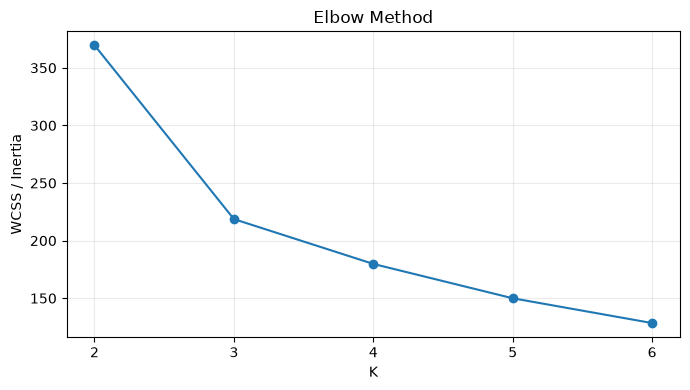

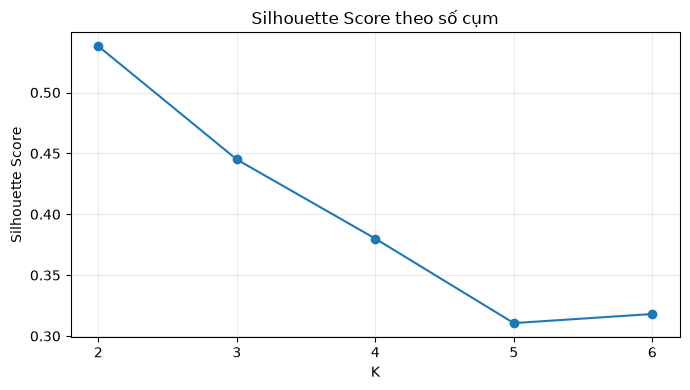

In [31]:
results = []
for k in range(2, 7):
    model = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=50,
        random_state=RANDOM_STATE,
    )
    labels = model.fit_predict(X_scaled)
    results.append({
        "K": k,
        "WCSS": model.inertia_,
        "Silhouette": silhouette_score(X_scaled, labels),
    })

k_results = pd.DataFrame(results)
display(k_results.round(4))

BEST_K = int(k_results.loc[k_results["Silhouette"].idxmax(), "K"])
print("K có Silhouette cao nhất:", BEST_K)

plt.figure(figsize=(7,4))
plt.plot(k_results["K"], k_results["WCSS"], marker="o")
plt.xlabel("K")
plt.ylabel("WCSS / Inertia")
plt.title("Elbow Method")
plt.xticks(k_results["K"])
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig("outputs/elbow_method.png", dpi=200, bbox_inches="tight")
plt.show()

plt.figure(figsize=(7,4))
plt.plot(k_results["K"], k_results["Silhouette"], marker="o")
plt.xlabel("K")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score theo số cụm")
plt.xticks(k_results["K"])
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig("outputs/silhouette_scores.png", dpi=200, bbox_inches="tight")
plt.show()

## 9. Chạy K-Means cuối cùng

Mặc định dùng K có Silhouette Score cao nhất. Nếu muốn **thử nghiệm riêng** với `K=4`, đổi `K_FINAL = 4`, nhưng khi viết paper cần nêu rõ lý do.

In [32]:
K_FINAL = BEST_K
# K_FINAL = 4

kmeans = KMeans(
    n_clusters=K_FINAL,
    init="k-means++",
    n_init=50,
    random_state=RANDOM_STATE,
)

df_model["Cluster"] = kmeans.fit_predict(X_scaled)
score = silhouette_score(X_scaled, df_model["Cluster"])

print("K cuối cùng:", K_FINAL)
print("Silhouette Score:", round(score, 4))
display(df_model["Cluster"].value_counts().sort_index().rename("Số quốc gia").to_frame())

K cuối cùng: 2
Silhouette Score: 0.5381


,Số quốc gia
Cluster,
0,130
1,46


## 10. Phân tích centroid

K-Means chỉ tạo `Cluster 0`, `Cluster 1`, ... Tên như “phát triển cao” hay “phát triển thấp” chỉ nên gán **sau khi** xem đặc trưng trung bình của từng cụm.

In [33]:
cluster_summary = df_model.groupby("Cluster")[FEATURES].mean().round(2)
display(cluster_summary)
cluster_summary.to_csv("outputs/cluster_summary.csv", encoding="utf-8-sig")

,GDP_per_capita,Life_expectancy,Mean_years_schooling,Internet_usage,Electricity_access
Cluster,,,,,
0,34519.08,76.66,10.74,84.30,99.21
1,4190.97,64.10,5.21,34.47,54.28


## 11. PCA trực quan hóa

PCA chỉ dùng để vẽ. K-Means vẫn chạy trên đầy đủ 5 biến đã chuẩn hóa.

PC1: 78.11%
PC2: 11.26%
Tổng: 89.37%


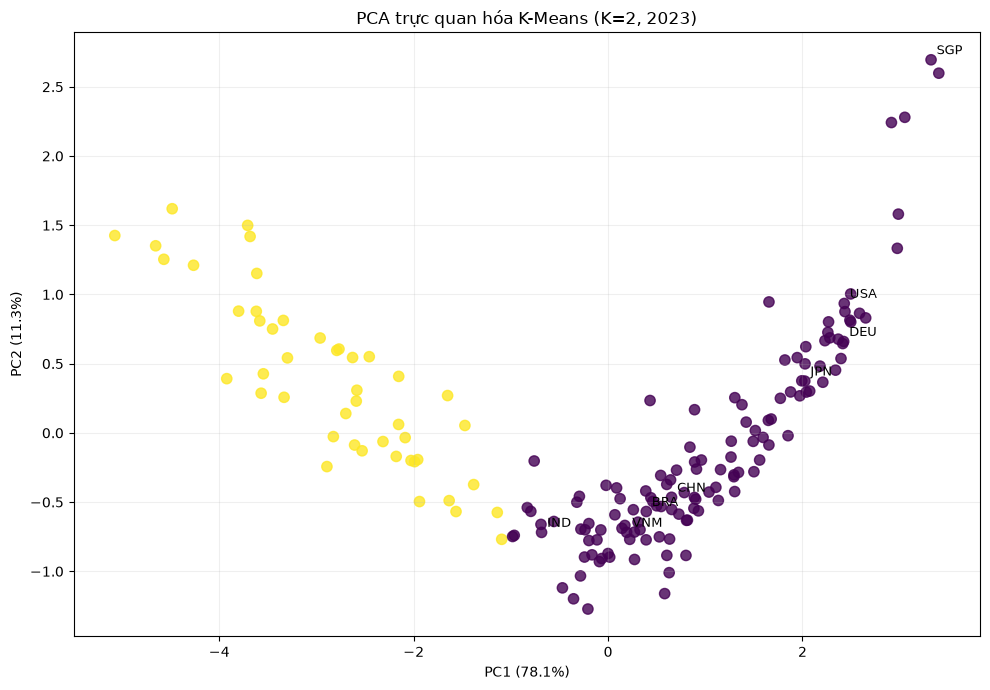

In [34]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

df_model["PC1"] = X_pca[:, 0]
df_model["PC2"] = X_pca[:, 1]

pc1, pc2 = pca.explained_variance_ratio_ * 100
print(f"PC1: {pc1:.2f}%")
print(f"PC2: {pc2:.2f}%")
print(f"Tổng: {pc1 + pc2:.2f}%")

plt.figure(figsize=(10,7))
plt.scatter(df_model["PC1"], df_model["PC2"], c=df_model["Cluster"], s=55, alpha=0.8)

for _, row in df_model[df_model["Code"].isin(["VNM","USA","CHN","JPN","DEU","IND","BRA","SGP"])].iterrows():
    plt.annotate(row["Code"], (row["PC1"], row["PC2"]), xytext=(4,4), textcoords="offset points", fontsize=9)

plt.xlabel(f"PC1 ({pc1:.1f}%)")
plt.ylabel(f"PC2 ({pc2:.1f}%)")
plt.title(f"PCA trực quan hóa K-Means (K={K_FINAL}, {YEAR})")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.savefig("outputs/pca_clusters.png", dpi=200, bbox_inches="tight")
plt.show()

## 12. Xem danh sách quốc gia trong từng cụm

In [35]:
for cluster_id in sorted(df_model["Cluster"].unique()):
    countries = df_model.loc[df_model["Cluster"].eq(cluster_id), "Entity"].sort_values().tolist()
    print(f"\nCLUSTER {cluster_id} — {len(countries)} quốc gia/đơn vị")
    print(", ".join(countries))


CLUSTER 0 — 130 quốc gia/đơn vị
Albania, Algeria, Andorra, Antigua and Barbuda, Argentina, Armenia, Australia, Austria, Azerbaijan, Bahamas, Bahrain, Bangladesh, Barbados, Belarus, Belgium, Belize, Bhutan, Bolivia, Bosnia and Herzegovina, Brazil, Brunei, Bulgaria, Cambodia, Canada, Cape Verde, Chile, China, Colombia, Costa Rica, Croatia, Cyprus, Czechia, Denmark, Dominica, Dominican Republic, Ecuador, Egypt, El Salvador, Estonia, Fiji, Finland, France, Gabon, Georgia, Germany, Greece, Grenada, Guatemala, Guyana, Honduras, Hong Kong, Hungary, Iceland, India, Indonesia, Iran, Iraq, Ireland, Israel, Italy, Jamaica, Japan, Jordan, Kazakhstan, Kiribati, Kuwait, Kyrgyzstan, Laos, Latvia, Lebanon, Libya, Lithuania, Luxembourg, Malaysia, Maldives, Malta, Marshall Islands, Mauritius, Mexico, Moldova, Mongolia, Montenegro, Morocco, Nauru, Netherlands, New Zealand, Nicaragua, North Macedonia, Norway, Oman, Palau, Palestine, Panama, Paraguay, Peru, Philippines, Poland, Portugal, Qatar, Romania, R

## 13. Đối chiếu với HDI

HDI không tham gia K-Means, vì vậy có thể dùng như một tham chiếu bên ngoài.

In [ ]:
hdi_summary = df_model.groupby("Cluster")["HDI"].agg(["count","mean","median","min","max"]).round(3)
display(hdi_summary)

plt.figure(figsize=(7,4))
hdi_summary["mean"].plot(kind="bar")
plt.xlabel("Cluster")
plt.ylabel("HDI trung bình")
plt.title("HDI trung bình theo cụm")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("outputs/hdi_by_cluster.png", dpi=200, bbox_inches="tight")
plt.show()

## 14. Phân tích Việt Nam

In [ ]:
vn = df_model[df_model["Code"].eq("VNM")].copy()

if vn.empty:
    print("Không tìm thấy Việt Nam sau bước merge.")
else:
    vn_row = vn.iloc[0]
    vn_cluster = int(vn_row["Cluster"])
    print("Việt Nam thuộc Cluster:", vn_cluster)
    display(vn[["Entity","Code","Year"] + FEATURES + ["HDI","Cluster"]])

    cluster_mean = df_model[df_model["Cluster"].eq(vn_cluster)][FEATURES + ["HDI"]].mean()
    comparison = pd.DataFrame({
        "Việt Nam": vn_row[FEATURES + ["HDI"]],
        "Trung bình cụm": cluster_mean,
    })
    display(comparison.round(2))
    comparison.to_csv("outputs/vietnam_vs_cluster.csv", encoding="utf-8-sig")

## 15. Xuất kết quả dùng cho paper

In [ ]:
k_results.to_csv("outputs/k_selection.csv", index=False, encoding="utf-8-sig")

export_cols = ["Entity","Code","Year"] + FEATURES + ["HDI","Cluster","PC1","PC2"]
df_model[export_cols].sort_values(["Cluster","Entity"]).to_csv(
    f"outputs/country_clusters_{YEAR}.csv", index=False, encoding="utf-8-sig"
)

summary = f"""K-MEANS OWID — KẾT QUẢ THỰC NGHIỆM
Năm: {YEAR}
Số quan sát dùng cho K-Means: {len(df_model)}
K được chọn: {K_FINAL}
Silhouette Score: {score:.4f}
PC1: {pc1:.2f}%
PC2: {pc2:.2f}%
PC1 + PC2: {pc1 + pc2:.2f}%
"""
if not vn.empty:
    summary += f"Cluster của Việt Nam: {int(vn.iloc[0]['Cluster'])}\n"

with open("outputs/experiment_summary.txt", "w", encoding="utf-8") as f:
    f.write(summary)

print(summary)
print("Đã lưu kết quả vào outputs/.")

## 16. Tải toàn bộ kết quả trên Google Colab (tùy chọn)

In [ ]:
import shutil
shutil.make_archive("kmeans_owid_outputs", "zip", "outputs")

try:
    from google.colab import files
    files.download("kmeans_owid_outputs.zip")
except ImportError:
    print("Đang chạy Jupyter local. File đã tạo: kmeans_owid_outputs.zip")

# Cách demo trước lớp

1. Cho xem các URL OWID để chứng minh nguồn dữ liệu.
2. Cho xem bảng sau merge: mỗi quốc gia là một dòng.
3. Giải thích StandardScaler.
4. Cho xem Elbow và Silhouette để chọn K.
5. Chạy K-Means và xem centroid.
6. Hiển thị PCA.
7. Đối chiếu HDI.
8. Phân tích riêng Việt Nam.

> **Lưu ý:** K-Means là học không giám sát nên notebook không dùng `train_test_split` theo cách của classification/regression. Đánh giá tập trung vào WCSS, Silhouette Score, cấu trúc centroid, trực quan PCA và đối chiếu bên ngoài bằng HDI.